# 05 · Selección del modelo ganador, prueba y Model Registry

**Pasos:**
0. **Versión de cada modelo que compite (por defecto o tuneada):** regla explícita en la sección 1. Si la mejora del tuning no supera la desviación entre pliegues, las dos versiones empatan en AUC-PR y decide la brecha (menos sobreajuste); si la brecha también es parecida, se queda la de por defecto, por simplicidad.
1. **Ganador frente al segundo mejor en CV:** media y desviación de la AUC-PR, más la comparación pareada por pliegue. Si la diferencia no supera la variación entre pliegues, decide la **métrica de negocio** (pérdida neta fuera de pliegue) y después el costo y la explicabilidad.
2. **Umbral de decisión elegido en la CV** con las predicciones fuera de pliegue (OOF): el que minimiza la pérdida neta = fraude no detectado + USD 5 por falsa alarma. **No se elige con la prueba.**
3. **Corridas finales (`fase=final`):** una para el ganador (`champion`) y otra para el segundo (`challenger`). En cada una:
   - el modelo se **reentrena con todo el entrenamiento** (todos los fraudes y el 5 % de las legítimas) usando la mejor configuración del tuning;
   - se **evalúa una sola vez en prueba** (jul-dic 2020, todas las filas, prevalencia real) con el umbral de la CV;
   - se guarda con **firma e `input_example`**, y **desde esa misma corrida** se registra en `centinela-modelo` con su alias.
4. **Referencia de negocio:** las reglas fijas del PSet 1 en el mismo período.
5. **Costo y explicabilidad:** tiempos de entrenamiento e inferencia e importancia por permutación, sobre los puntajes ya calculados (sin volver a evaluar).
6. **Exportación** de las corridas activas del experimento a `docs/corridas.csv`.

La reproducción exacta de la métrica desde `models:/centinela-modelo@champion` está en un notebook aparte, **`06_reproduccion.ipynb`**, que no depende de este.

In [1]:
import sys, json, time, ast, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mlflow
from mlflow import MlflowClient
from mlflow.entities import ViewType
from IPython.display import Image, display
from sklearn.metrics import precision_recall_curve
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

from datos import cargar_obt, metadatos_snapshot
from pipeline import (SEMILLA, COSTO_FALSA_ALARMA, ReglasFijas, construir_modelo, dividir, CVTemporalSubmuestreada,
                      evaluar_cv, auc_pr, resumen_negocio)
from experimento import (configurar_mlflow, borrar_corridas, etiquetar, registrar_datos, registrar_modelo,
                         entrenar_final, commit_git, NOMBRE_MODELO, EXPERIMENTO)

DOCS = Path.cwd().parent / "docs" / "seleccion"
DOCS.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(DOCS / nombre, dpi=120); plt.close(fig)
    display(Image(filename=str(DOCS / nombre)))

print("MLflow:", configurar_mlflow(), "| commit:", commit_git())
print("corridas 'final' previas borradas:", borrar_corridas(["final"]))
cliente = MlflowClient()
df = cargar_obt()
X_ent, y_ent, X_pru, y_pru, ent, pru = dividir(df)
monto_ent, monto_pru = ent["amt"].to_numpy(), pru["amt"].to_numpy()
cv = CVTemporalSubmuestreada()
mejores = json.loads((Path.cwd().parent / "docs" / "tuning" / "mejores_para_seleccion.json").read_text(encoding="utf-8"))
pd.DataFrame(mejores)[["modelo", "default_cv_auc_pr", "default_cv_std", "tuned_cv_auc_pr", "tuned_cv_std", "tuned_brecha", "mejora", "mejora_cuenta"]]

MLflow: http://127.0.0.1:5055 | commit: 7e6a264-con-cambios


corridas 'final' previas borradas: 0


,modelo,default_cv_auc_pr,default_cv_std,tuned_cv_auc_pr,tuned_cv_std,tuned_brecha,mejora,mejora_cuenta
0,hist_gradient_boosting,0.961244,0.016265,0.963704,0.015132,0.034638,0.002460,False
1,random_forest,0.940629,0.020175,0.939359,0.018940,0.045742,-0.001270,False
2,mlp,0.917724,0.023298,0.928421,0.025519,0.054886,0.010697,False


## 1. Qué versión de cada modelo compite: por defecto o tuneada

**Regla:**
1. Si la **mejora** del tuning (AUC-PR CV tuneada − por defecto) **supera la desviación entre pliegues** (la mayor de las dos versiones), compite la **tuneada**.
2. Si no la supera, las dos versiones se consideran **empatadas en AUC-PR** y compite la de **menor brecha** entrenamiento − CV, es decir, la que sobreajusta menos.
3. Si las brechas también son **parecidas** (difieren en menos de **0,01** de AUC-PR), compite la **de por defecto**, por simplicidad: menos hiperparámetros que justificar y mantener.

El margen de 0,01 para "brecha parecida" es menor que la desviación típica entre pliegues de estos modelos (~0,015–0,02, ver la tabla). Una diferencia de brecha más chica no se puede distinguir del ruido.

Los datos de la versión por defecto salen de las corridas `candidato` del notebook 03 y los de la tuneada, del notebook 04 (MLflow y `docs/tuning/`).

In [2]:
BASE = {
    "hist_gradient_boosting": lambda **p: HistGradientBoostingClassifier(random_state=SEMILLA, **p),
    "random_forest": lambda **p: RandomForestClassifier(n_jobs=-1, random_state=SEMILLA, **p),
    "mlp": lambda **p: MLPClassifier(random_state=SEMILLA, **p),
}
def convertir(v):
    # Texto guardado en el tuning -> valor de Python (None, números, tuplas, booleanos; si no, texto)
    try:
        return ast.literal_eval(v)
    except (ValueError, SyntaxError):
        return v
def params_de(m):
    return {k: convertir(v) for k, v in json.loads(m["mejores_params"]).items()}

MARGEN_BRECHA = 0.01
exp = mlflow.get_experiment_by_name(EXPERIMENTO)
cand = mlflow.search_runs([exp.experiment_id], filter_string="tags.fase = 'candidato'").set_index("tags.mlflow.runName")
filas, elegido = [], {}
for m in mejores:
    nombre = m["modelo"]
    d = cand.loc[nombre]
    d_media, d_std, d_brecha = d["metrics.cv_auc_pr_media"], d["metrics.cv_auc_pr_std"], d["metrics.brecha_auc_pr"]
    t_media, t_std, t_brecha = m["tuned_cv_auc_pr"], m["tuned_cv_std"], m["tuned_brecha"]
    mejora, ruido = t_media - d_media, max(t_std, d_std)
    if mejora > ruido:
        version, motivo = "tuneada", f"mejora {mejora:+.4f} > desviación {ruido:.4f}"
    elif abs(t_brecha - d_brecha) >= MARGEN_BRECHA:
        version = "tuneada" if t_brecha < d_brecha else "por_defecto"
        motivo = f"empate en AUC-PR (mejora {mejora:+.4f} ≤ desv. {ruido:.4f}); menor brecha ({min(t_brecha, d_brecha):.4f} vs {max(t_brecha, d_brecha):.4f})"
    else:
        version = "por_defecto"
        motivo = f"empate en AUC-PR (mejora {mejora:+.4f} ≤ desv. {ruido:.4f}) y brechas parecidas (dif. {abs(t_brecha - d_brecha):.4f} < {MARGEN_BRECHA}); por simplicidad"
    params = params_de(m) if version == "tuneada" else {}
    elegido[nombre] = {"familia": m["familia"], "version": version, "params": params,
                       "cv_auc_pr_media": t_media if version == "tuneada" else d_media,
                       "cv_auc_pr_std": t_std if version == "tuneada" else d_std,
                       "brecha": t_brecha if version == "tuneada" else d_brecha,
                       "run_id_origen": m["run_id_padre"] if version == "tuneada" else d["run_id"]}
    filas.append({"modelo": nombre, "defecto_cv": f"{d_media:.4f} ± {d_std:.4f}", "defecto_brecha": round(d_brecha, 4),
                  "tuneada_cv": f"{t_media:.4f} ± {t_std:.4f}", "tuneada_brecha": round(t_brecha, 4),
                  "mejora": round(mejora, 4), "desviacion_ref": round(ruido, 4), "mejora_supera_desv": mejora > ruido,
                  "version_elegida": version, "motivo": motivo,
                  "cv_version_elegida": f"{elegido[nombre]['cv_auc_pr_media']:.4f} ± {elegido[nombre]['cv_auc_pr_std']:.4f}"})
tabla_versiones = pd.DataFrame(filas).sort_values("cv_version_elegida", ascending=False)
tabla_versiones.to_csv(DOCS / "version_elegida_por_modelo.csv", index=False)
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(tabla_versiones)

,modelo,defecto_cv,defecto_brecha,tuneada_cv,tuneada_brecha,mejora,desviacion_ref,mejora_supera_desv,version_elegida,motivo,cv_version_elegida
0,hist_gradient_boosting,0.9612 ± 0.0163,0.0368,0.9637 ± 0.0151,0.0346,0.0025,0.0163,False,por_defecto,empate en AUC-PR (mejora +0.0025 ≤ desv. 0.0163) y brechas parecidas (dif. 0.0021 < 0.01); por simplicidad,0.9612 ± 0.0163
1,random_forest,0.9406 ± 0.0202,0.0594,0.9394 ± 0.0189,0.0457,-0.0013,0.0202,False,tuneada,empate en AUC-PR (mejora -0.0013 ≤ desv. 0.0202); menor brecha (0.0457 vs 0.0594),0.9394 ± 0.0189
2,mlp,0.9177 ± 0.0233,0.0823,0.9284 ± 0.0255,0.0549,0.0107,0.0255,False,tuneada,empate en AUC-PR (mejora +0.0107 ≤ desv. 0.0255); menor brecha (0.0549 vs 0.0823),0.9284 ± 0.0255


## 2. Ganador frente al segundo mejor en la CV (con la versión elegida de cada modelo)

In [3]:
orden = sorted(elegido, key=lambda k: elegido[k]["cv_auc_pr_media"], reverse=True)
# Se recalcula la CV de los dos mejores (misma semilla, mismos pliegues) para tener sus predicciones OOF
cvres = {}
for nombre in orden[:2]:
    t0 = time.perf_counter()
    cvres[nombre] = evaluar_cv(construir_modelo(BASE[nombre](**elegido[nombre]["params"])), X_ent, y_ent, cv, monto=monto_ent)
    r = cvres[nombre]
    print(f"{nombre:24s} ({elegido[nombre]['version']}) CV {r['cv_auc_pr_media']:.4f} ± {r['cv_auc_pr_std']:.4f} "
          f"(registrado: {elegido[nombre]['cv_auc_pr_media']:.4f}) | pérdida OOF ${r['cv_perdida_neta_oof']:,.0f} "
          f"| umbral {r['cv_umbral_optimo']:.4f} | {time.perf_counter()-t0:.0f} s")

hist_gradient_boosting   (por_defecto) CV 0.9612 ± 0.0163 (registrado: 0.9612) | pérdida OOF $34,325 | umbral 0.2400 | 21 s


random_forest            (tuneada) CV 0.9394 ± 0.0189 (registrado: 0.9394) | pérdida OOF $43,290 | umbral 0.4438 | 56 s


In [4]:
a, b = orden[0], orden[1]
ra, rb = cvres[a], cvres[b]
dif = ra["cv_auc_pr_media"] - rb["cv_auc_pr_media"]
ruido = max(ra["cv_auc_pr_std"], rb["cv_auc_pr_std"])
pareado = ra["pliegues"]["auc_pr_validacion"].to_numpy() - rb["pliegues"]["auc_pr_validacion"].to_numpy()
if dif > ruido:
    ganador, segundo, razon = a, b, f"AUC-PR CV mayor en {dif:.4f}, más que la desviación entre pliegues ({ruido:.4f})"
else:
    ganador, segundo = (a, b) if ra["cv_perdida_neta_oof"] <= rb["cv_perdida_neta_oof"] else (b, a)
    razon = (f"diferencia de AUC-PR CV ({dif:+.4f}) menor que la desviación entre pliegues ({ruido:.4f}): empate técnico; "
             f"decide la pérdida neta OOF en CV (${cvres[ganador]['cv_perdida_neta_oof']:,.0f} vs ${cvres[segundo]['cv_perdida_neta_oof']:,.0f})")
comparacion_cv = pd.DataFrame({
    m: {"cv_auc_pr_media": cvres[m]["cv_auc_pr_media"], "cv_auc_pr_std": cvres[m]["cv_auc_pr_std"],
        **{f"pliegue_{k}": v for k, v in enumerate(cvres[m]["pliegues"]["auc_pr_validacion"])},
        "version": elegido[m]["version"], "cv_perdida_neta_oof": cvres[m]["cv_perdida_neta_oof"], "cv_umbral_optimo": cvres[m]["cv_umbral_optimo"],
        "segundos_entrenamiento_cv": cvres[m]["segundos_entrenamiento"], "segundos_prediccion_cv": cvres[m]["segundos_prediccion"]}
    for m in (a, b)}).T
comparacion_cv.to_csv(DOCS / "ganador_vs_segundo_cv.csv")
print(f"Diferencia pareada por pliegue ({a} - {b}):", np.round(pareado, 4), "| pliegues a favor de", a, ":", int((pareado > 0).sum()), "de 3")
print("GANADOR:", ganador, "| SEGUNDO:", segundo, "\nRazón:", razon)
comparacion_cv.round(4)

Diferencia pareada por pliegue (hist_gradient_boosting - random_forest): [0.025  0.0233 0.0174] | pliegues a favor de hist_gradient_boosting : 3 de 3
GANADOR: hist_gradient_boosting | SEGUNDO: random_forest 
Razón: AUC-PR CV mayor en 0.0219, más que la desviación entre pliegues (0.0189)


,cv_auc_pr_media,cv_auc_pr_std,pliegue_0,pliegue_1,pliegue_2,version,cv_perdida_neta_oof,cv_umbral_optimo,segundos_entrenamiento_cv,segundos_prediccion_cv
hist_gradient_boosting,0.961244,0.016265,0.938595,0.969093,0.976045,por_defecto,34324.81,0.239993,5.775314,13.603178
random_forest,0.939359,0.01894,0.913621,0.945806,0.958651,tuneada,43289.54,0.443802,48.282336,6.43502


## 3. Umbral de decisión según el costo de cada error (elegido en la CV)

- Un **falso negativo** cuesta el **monto completo** del fraude: el banco lo reembolsa.
- Un **falso positivo** cuesta **USD 5**: verificación, llamada y fricción con el cliente (supuesto del PSet 1).

Como un fraude típico vale mucho más que USD 5, el umbral óptimo queda **muy por debajo de 0,5**. Se elige con las predicciones OOF de la CV, que tienen la prevalencia real.

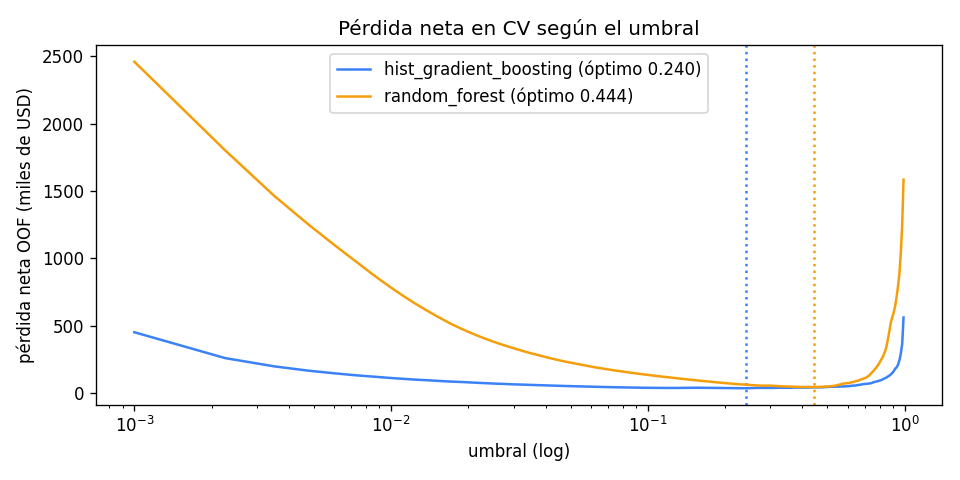

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for m, color in ((ganador, "#3b82f6"), (segundo, "#f59e0b")):
    r = cvres[m]; yy = y_ent.values[r["oof_indices"]]; mm = monto_ent[r["oof_indices"]]
    umbrales = np.r_[np.linspace(0.001, 0.05, 40), np.linspace(0.05, 0.99, 80)]
    perd = [resumen_negocio(yy, r["oof_score"], mm, u)["perdida_neta"] for u in umbrales]
    ax.plot(umbrales, np.array(perd) / 1e3, label=f"{m} (óptimo {r['cv_umbral_optimo']:.3f})", color=color)
    ax.axvline(r["cv_umbral_optimo"], color=color, ls=":")
ax.set_xscale("log"); ax.set_xlabel("umbral (log)"); ax.set_ylabel("pérdida neta OOF (miles de USD)")
ax.set_title("Pérdida neta en CV según el umbral"); ax.legend()
guardar(fig, "perdida_vs_umbral_cv.png")

## 4. Corridas finales: reentrenamiento, evaluación única en prueba y registro

Cada modelo tiene **una** corrida `fase=final` (el champion y el challenger por separado). Dentro de ella:
1. se reentrena con la mejor configuración del tuning sobre todo el entrenamiento;
2. se puntúa **una sola vez** la prueba completa (525.661 filas) y se aplica el umbral de la CV;
3. se guarda el pipeline con firma e `input_example` y se **registra desde esa corrida** en `centinela-modelo`, con su alias.

Los puntajes de prueba se guardan en memoria para los gráficos y la explicabilidad, que no vuelven a evaluar.

In [6]:
prueba, modelos, registro = {}, {}, {}
for m, alias in ((ganador, "champion"), (segundo, "challenger")):
    with mlflow.start_run(run_name=f"final_{alias}_{m}") as run:
        etiquetar("final", elegido[m]["familia"], alias=alias, modelo=m, version_elegida=elegido[m]["version"],
                  origen_run_id=elegido[m]["run_id_origen"])
        registrar_datos()
        est = BASE[m](**elegido[m]["params"])
        mlflow.log_params({f"modelo__{k}": str(v) for k, v in est.get_params().items() if not callable(v) and len(str(v)) < 250})
        mlflow.log_params({"version_elegida": elegido[m]["version"], "modelo_clase": type(est).__name__})
        u = cvres[m]["cv_umbral_optimo"]
        mlflow.log_params({"umbral_decision": u, "umbral_elegido_en": "CV (predicciones OOF), minimizando la pérdida neta",
                           "costo_falsa_alarma_usd": COSTO_FALSA_ALARMA})
        # (1) reentrenamiento en todo el entrenamiento
        modelo, met_final = entrenar_final(construir_modelo(est), X_ent, y_ent)
        # (2) evaluación única en prueba
        t0 = time.perf_counter(); score = modelo.predict_proba(X_pru)[:, 1]; t_inf = time.perf_counter() - t0
        res = {"auc_pr_prueba": auc_pr(y_pru, score), **resumen_negocio(y_pru, score, monto_pru, u),
               "segundos_inferencia_prueba": t_inf, "ms_por_1000_transacciones": 1000 * t_inf / len(X_pru) * 1000}
        mlflow.log_metrics({"cv_auc_pr_media": cvres[m]["cv_auc_pr_media"], "cv_auc_pr_std": cvres[m]["cv_auc_pr_std"],
                            "cv_perdida_neta_oof": cvres[m]["cv_perdida_neta_oof"], **met_final,
                            **{f"prueba_{k}": float(v) for k, v in res.items()}})
        mlflow.set_tag("razon_seleccion", razon)
        # (3) artefacto con firma + input_example, registrado desde esta corrida
        info_modelo = registrar_modelo(modelo, X_ent, nombre_registro=NOMBRE_MODELO)
        version = info_modelo.registered_model_version
        cliente.set_registered_model_alias(NOMBRE_MODELO, alias, version)
        cliente.set_model_version_tag(NOMBRE_MODELO, version, "umbral_decision", str(u))
        prueba[m] = {**res, "umbral_cv": u, "segundos_entrenamiento_final": met_final["final_segundos_entrenamiento"]}
        modelos[m], prueba[m]["_score"] = modelo, score
        registro[alias] = {"modelo": m, "version_elegida": elegido[m]["version"], "run_id": run.info.run_id, "version_registro": int(version),
                           "model_uri": f"models:/{NOMBRE_MODELO}@{alias}", "prueba_auc_pr": res["auc_pr_prueba"],
                           "prueba_perdida_neta": res["perdida_neta"], "umbral": u, "run_id_origen": elegido[m]["run_id_origen"]}
    print(f"{alias:10s} {m:24s} ({elegido[m]['version']}) run_id {run.info.run_id} | {NOMBRE_MODELO} versión {version} | "
          f"AUC-PR prueba {res['auc_pr_prueba']:.4f} | pérdida neta ${res['perdida_neta']:,.0f}")
(DOCS / "registro_modelos.json").write_text(json.dumps(registro, indent=2, ensure_ascii=False), encoding="utf-8")
for alias in ("champion", "challenger"):
    v = cliente.get_model_version_by_alias(NOMBRE_MODELO, alias)
    print(f"Registro: {NOMBRE_MODELO}@{alias} -> versión {v.version}, run_id {v.run_id} (corrida final: {v.run_id == registro[alias]['run_id']})")
pd.DataFrame(registro).T

Successfully registered model 'centinela-modelo'.
2026/11/19 01:28:26 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: centinela-modelo, version 1


Created version '1' of model 'centinela-modelo'.


2026/11/19 01:28:26 INFO mlflow.tracking._tracking_service.client: 🏃 View run final_champion_hist_gradient_boosting at: http://127.0.0.1:5055/#/experiments/1/runs/70bfd857902b4cc188d52a94d934c442.


2026/11/19 01:28:26 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://127.0.0.1:5055/#/experiments/1.


champion   hist_gradient_boosting   (por_defecto) run_id 70bfd857902b4cc188d52a94d934c442 | centinela-modelo versión 1 | AUC-PR prueba 0.9655 | pérdida neta $14,649


Registered model 'centinela-modelo' already exists. Creating a new version of this model...
2026/11/19 01:29:12 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: centinela-modelo, version 2


Created version '2' of model 'centinela-modelo'.


2026/11/19 01:29:13 INFO mlflow.tracking._tracking_service.client: 🏃 View run final_challenger_random_forest at: http://127.0.0.1:5055/#/experiments/1/runs/24f82ec738f8412c9de7599f4e0051a2.


2026/11/19 01:29:13 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://127.0.0.1:5055/#/experiments/1.


challenger random_forest            (tuneada) run_id 24f82ec738f8412c9de7599f4e0051a2 | centinela-modelo versión 2 | AUC-PR prueba 0.9404 | pérdida neta $17,834
Registro: centinela-modelo@champion -> versión 1, run_id 70bfd857902b4cc188d52a94d934c442 (corrida final: True)
Registro: centinela-modelo@challenger -> versión 2, run_id 24f82ec738f8412c9de7599f4e0051a2 (corrida final: True)


,modelo,version_elegida,run_id,version_registro,model_uri,prueba_auc_pr,prueba_perdida_neta,umbral,run_id_origen
champion,hist_gradient_boosting,por_defecto,70bfd857902b4cc188d52a94d934c442,1,models:/centinela-modelo@champion,0.96547,14649.03,0.239993,fb65308c5c97454c9567082b30206b3c
challenger,random_forest,tuneada,24f82ec738f8412c9de7599f4e0051a2,2,models:/centinela-modelo@challenger,0.940403,17834.33,0.443802,54a38a3975784db4bc9de3669ac509d8


## 5. Comparación en prueba con la línea de negocio (reglas fijas del PSet 1)

In [7]:
reglas = ReglasFijas().fit(X_ent)
s_reglas = reglas.predict_proba(X_pru)[:, 1]
filas = {m: {c: v for c, v in prueba[m].items() if c != "_score"} for m in (ganador, segundo)}
filas["reglas_fijas_pset1"] = {"auc_pr_prueba": auc_pr(y_pru, s_reglas), "umbral_cv": 1.0, **resumen_negocio(y_pru, s_reglas, monto_pru, 1.0)}
filas["sin_modelo_aprobar_todo"] = {"auc_pr_prueba": float(y_pru.mean()), "umbral_cv": np.inf,
                                    **resumen_negocio(y_pru, np.zeros(len(y_pru)), monto_pru, 1.0)}
tabla_prueba = pd.DataFrame(filas).T
perdida_reglas = float(tabla_prueba.loc["reglas_fijas_pset1", "perdida_neta"])
tabla_prueba["reduccion_perdida_vs_reglas_pct"] = 100 * (1 - tabla_prueba["perdida_neta"].astype(float) / perdida_reglas)
tabla_prueba["meta_pset1_30pct_menos_perdida"] = tabla_prueba["reduccion_perdida_vs_reglas_pct"] >= 30
tabla_prueba["meta_pset1_max_1pct_legitimas_alertadas"] = tabla_prueba["pct_legitimas_alertadas"].astype(float) <= 1
tabla_prueba.to_csv(DOCS / "evaluacion_prueba.csv")
tabla_prueba.round(4)

,auc_pr_prueba,perdida_neta,fraude_no_detectado_usd,falsas_alarmas,fraudes_detectados,fraudes_totales,recall,precision,pct_legitimas_alertadas,segundos_inferencia_prueba,ms_por_1000_transacciones,umbral_cv,segundos_entrenamiento_final,reduccion_perdida_vs_reglas_pct,meta_pset1_30pct_menos_perdida,meta_pset1_max_1pct_legitimas_alertadas
hist_gradient_boosting,0.9655,14649.03,7134.03,1503.0,1959.0,2012.0,0.9737,0.5659,0.2870,7.2436,13.780,0.2400,3.4392,98.1205,True,True
random_forest,0.9404,17834.33,10424.33,1482.0,1920.0,2012.0,0.9543,0.5644,0.2830,3.5624,6.777,0.4438,39.0746,97.7119,True,True
reglas_fijas_pset1,0.0095,779426.12,6381.12,154609.0,1670.0,2012.0,0.8300,0.0107,29.5253,NaN,NaN,1.0000,NaN,0.0000,False,False
sin_modelo_aprobar_todo,0.0038,1060049.75,1060049.75,0.0,0.0,2012.0,0.0000,0.0000,0.0000,NaN,NaN,inf,NaN,-36.0039,False,True


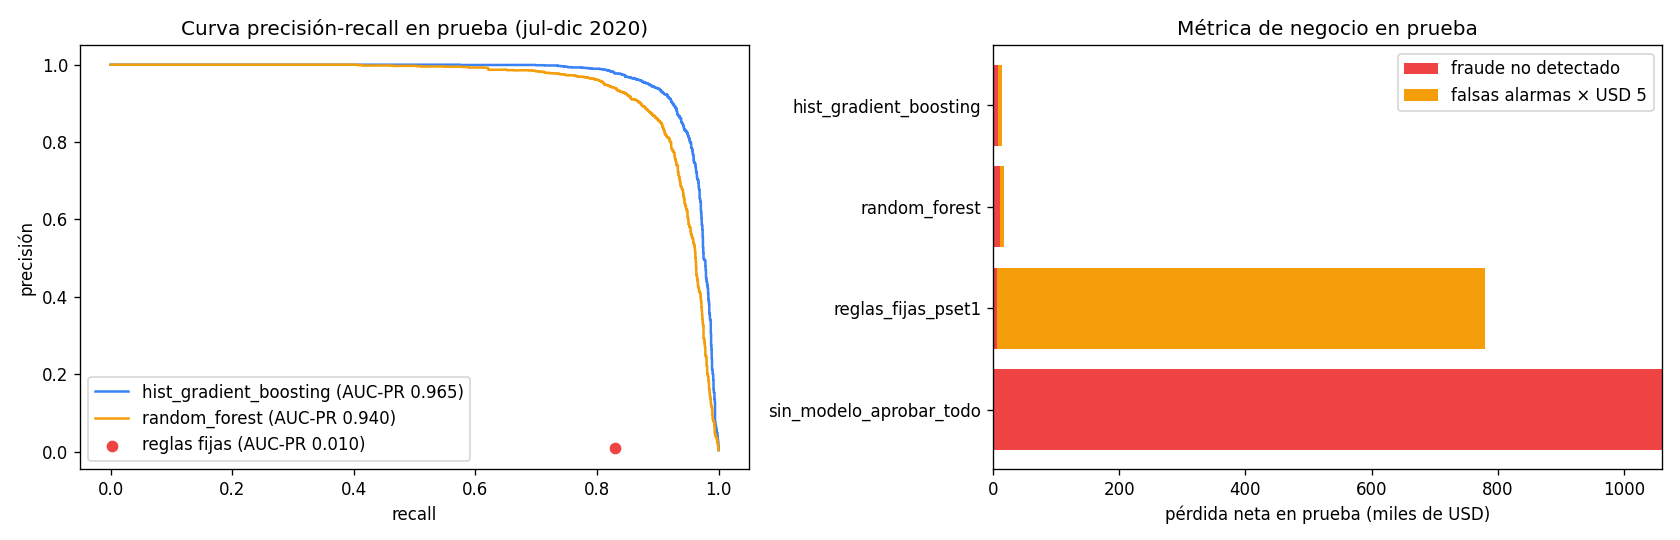

Alertas por día en prueba (hist_gradient_boosting): 18.8 (184 días)
Alertas por día en prueba (reglas_fijas_pset1): 849.3 (184 días)


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for m, color in ((ganador, "#3b82f6"), (segundo, "#f59e0b")):
    p, r, _ = precision_recall_curve(y_pru, prueba[m]["_score"])
    ax[0].plot(r, p, color=color, label=f"{m} (AUC-PR {prueba[m]['auc_pr_prueba']:.3f})")
pr_, rr_, _ = precision_recall_curve(y_pru, s_reglas)
ax[0].scatter(rr_[1], pr_[1], color="#ef4444", zorder=3, label=f"reglas fijas (AUC-PR {filas['reglas_fijas_pset1']['auc_pr_prueba']:.3f})")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precisión"); ax[0].set_title("Curva precisión-recall en prueba (jul-dic 2020)"); ax[0].legend()
orden = ["sin_modelo_aprobar_todo", "reglas_fijas_pset1", segundo, ganador]
partes = tabla_prueba.loc[orden, ["fraude_no_detectado_usd", "falsas_alarmas"]].astype(float)
ax[1].barh(orden, partes["fraude_no_detectado_usd"] / 1e3, color="#ef4444", label="fraude no detectado")
ax[1].barh(orden, partes["falsas_alarmas"] * COSTO_FALSA_ALARMA / 1e3, left=partes["fraude_no_detectado_usd"] / 1e3, color="#f59e0b", label="falsas alarmas × USD 5")
ax[1].set_xlabel("pérdida neta en prueba (miles de USD)"); ax[1].set_title("Métrica de negocio en prueba"); ax[1].legend()
guardar(fig, "prueba_pr_y_perdida.png")
dias = pru["fecha"].nunique()
for m in (ganador, "reglas_fijas_pset1"):
    print(f"Alertas por día en prueba ({m}): {(filas[m]['falsas_alarmas'] + filas[m]['fraudes_detectados']) / dias:.1f} ({dias} días)")

## 6. Costo y explicabilidad

- **Costo:** se comparan los segundos de entrenamiento (en la CV y en el reentrenamiento final) y de inferencia sobre toda la prueba.
- **Explicabilidad:** importancia por permutación de las **21 variables de entrada**, medida como la caída de la AUC-PR al desordenar cada una. Se calcula sobre una muestra de la prueba con todos sus fraudes. Es una explicación posterior a la selección: no influye en la elección del modelo ni del umbral.

hist_gradient_boosting: permutación en 21 s


random_forest: permutación en 19 s


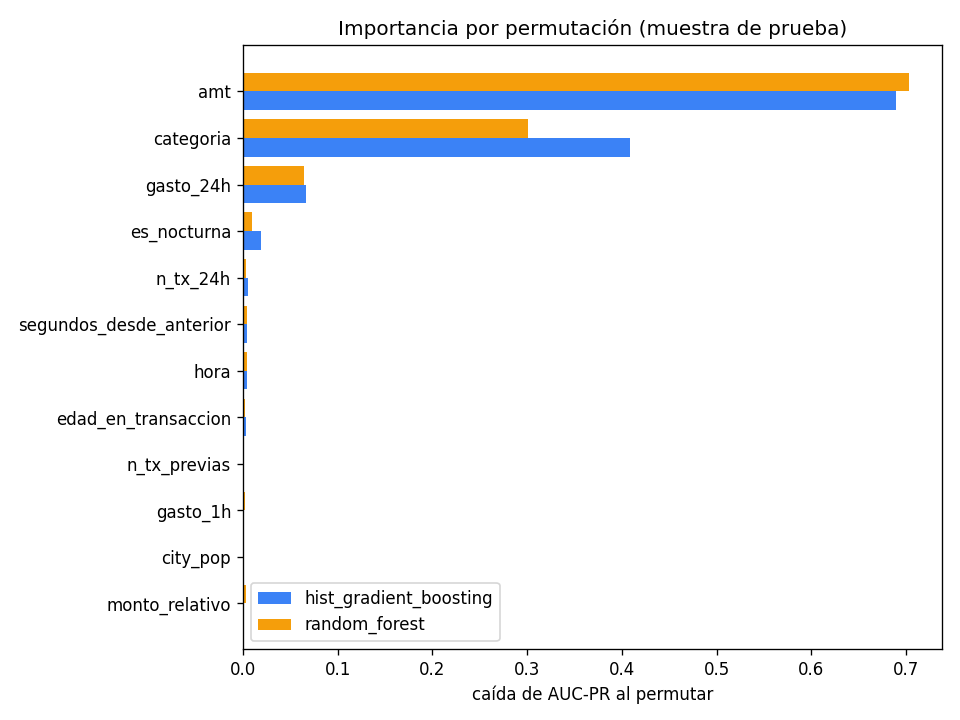

,segundos_entrenamiento_cv_3_pliegues,segundos_entrenamiento_final,segundos_inferencia_525k_filas,ms_por_1000_transacciones
hist_gradient_boosting,5.775,3.439,7.244,13.780
random_forest,48.282,39.075,3.562,6.777


,hist_gradient_boosting,random_forest
amt,0.6893,0.7028
categoria,0.4088,0.3010
gasto_24h,0.0670,0.0641
es_nocturna,0.0189,0.0097
n_tx_24h,0.0057,0.0030
segundos_desde_anterior,0.0044,0.0045
hora,0.0043,0.0044
edad_en_transaccion,0.0033,0.0022
n_tx_previas,0.0008,0.0007
gasto_1h,0.0006,0.0024


In [9]:
rng = np.random.default_rng(SEMILLA)
idx_fr = np.where(y_pru.values == 1)[0]; idx_le = rng.choice(np.where(y_pru.values == 0)[0], 40_000, replace=False)
idx = np.sort(np.concatenate([idx_fr, idx_le]))
imp = {}
for m in (ganador, segundo):
    t0 = time.perf_counter()
    pi = permutation_importance(modelos[m], X_pru.iloc[idx], y_pru.values[idx], scoring="average_precision",
                                n_repeats=3, random_state=SEMILLA, n_jobs=1)
    imp[m] = pd.Series(pi.importances_mean, index=X_pru.columns)
    print(f"{m}: permutación en {time.perf_counter()-t0:.0f} s")
imp_df = pd.DataFrame(imp).sort_values(ganador, ascending=False)
imp_df.to_csv(DOCS / "importancia_permutacion.csv")
fig, ax = plt.subplots(figsize=(8, 6))
top = imp_df.head(12).iloc[::-1]
ax.barh(np.arange(len(top)) - .2, top[ganador], .4, label=ganador, color="#3b82f6")
ax.barh(np.arange(len(top)) + .2, top[segundo], .4, label=segundo, color="#f59e0b")
ax.set_yticks(np.arange(len(top)), top.index); ax.set_xlabel("caída de AUC-PR al permutar"); ax.legend()
ax.set_title("Importancia por permutación (muestra de prueba)")
guardar(fig, "importancia_permutacion.png")
costo = pd.DataFrame({m: {"segundos_entrenamiento_cv_3_pliegues": cvres[m]["segundos_entrenamiento"],
                          "segundos_entrenamiento_final": prueba[m]["segundos_entrenamiento_final"],
                          "segundos_inferencia_525k_filas": prueba[m]["segundos_inferencia_prueba"],
                          "ms_por_1000_transacciones": prueba[m]["ms_por_1000_transacciones"]} for m in (ganador, segundo)}).T
costo.to_csv(DOCS / "costo_modelos.csv")
display(costo.round(3))
imp_df.head(10).round(4)

## 7. Exportar las corridas del experimento a `docs/corridas.csv`

Solo las corridas **activas**: se excluyen las borradas, por ejemplo las de la ejecución del tuning que se cortó al cerrarse el Codespace. Se dejan columnas útiles: identificación, fase, familia, métricas de CV y de prueba, datos y duración.

In [10]:
exp = mlflow.get_experiment_by_name(EXPERIMENTO)
todas = mlflow.search_runs([exp.experiment_id], run_view_type=ViewType.ACTIVE_ONLY, max_results=50000).sort_values("start_time")
columnas = {
    "run_id": "run_id", "tags.mlflow.runName": "nombre", "tags.fase": "fase", "tags.familia": "familia",
    "tags.modelo": "modelo", "tags.rol": "rol", "tags.alias": "alias", "tags.mlflow.parentRunId": "run_id_padre",
    "status": "estado", "metrics.auc_pr_entrenamiento": "auc_pr_entrenamiento", "metrics.cv_auc_pr_media": "cv_auc_pr_media",
    "metrics.cv_auc_pr_std": "cv_auc_pr_std", "metrics.brecha_auc_pr": "brecha_auc_pr",
    "metrics.segundos_entrenamiento": "segundos_entrenamiento_cv", "metrics.cv_perdida_neta_oof": "cv_perdida_neta_oof",
    "metrics.cv_umbral_optimo": "cv_umbral_optimo", "metrics.mejora_vs_default": "mejora_vs_default",
    "metrics.muestra_auc_pr_llm": "muestra_auc_pr_llm", "metrics.prueba_auc_pr_prueba": "prueba_auc_pr",
    "metrics.prueba_perdida_neta": "prueba_perdida_neta", "metrics.prueba_recall": "prueba_recall",
    "metrics.prueba_precision": "prueba_precision", "metrics.prueba_falsas_alarmas": "prueba_falsas_alarmas",
    "params.modelo_clase": "modelo_clase", "params.datos_sha256": "datos_sha256", "params.datos_fecha_corte": "datos_fecha_corte",
    "tags.git_commit": "git_commit", "start_time": "inicio", "end_time": "fin",
}
corridas = todas[[c for c in columnas if c in todas.columns]].rename(columns=columnas)
corridas["duracion_s"] = (pd.to_datetime(corridas["fin"]) - pd.to_datetime(corridas["inicio"])).dt.total_seconds().round(1)
ruta = Path.cwd().parent / "docs" / "corridas.csv"
corridas.to_csv(ruta, index=False)
print(f"{len(corridas)} corridas activas exportadas a docs/{ruta.name} | borradas excluidas: "
      f"{len(mlflow.search_runs([exp.experiment_id], run_view_type=ViewType.DELETED_ONLY, max_results=50000))}")
corridas.groupby("fase").size().rename("corridas").to_frame()

102 corridas activas exportadas a docs/corridas.csv | borradas excluidas: 43


,corridas
fase,
baseline,2
candidato,5
final,2
tuning,93
